# 0. Data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from nba_api.stats.endpoints import playercareerstats

from xppg import data, plotting
from xppg.raw import fetch, PROJECT_ROOT

plotting.use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## Download

In [2]:
P, T, R = [], [], []
for season in data.SEASONS:
    live = season == data.IN_PROGRESS
    t = data.team_games(season, refresh=live)
    P.append(data.player_games(season, refresh=live))
    T.append(t)
    R.append(data.rosters(season, sorted(t.team_id.unique()), refresh=live))
P, T, R = (pd.concat(x, ignore_index=True) for x in (P, T, R))
M = data.player_movement()
debut = data.debuts()

team_abbr = T.drop_duplicates("team_id").set_index("team_id").team_abbreviation
R["team"] = R.team_id.map(team_abbr)
season_start = T.groupby("season").game_date.min()
season_end = T.groupby("season").game_date.max()

pd.DataFrame({
    "player-game rows": P.groupby("season").size(),
    "players who played": P.groupby("season").player_id.nunique(),
    "team-game rows": T.groupby("season").size(),
    "roster rows": R.groupby("season").size(),
})

,player-game rows,players who played,team-game rows,roster rows
season,,,,
2020-21,23054,540,2160,503
2021-22,26039,605,2460,506
2022-23,25895,539,2460,508
2023-24,26401,572,2460,532
2024-25,26306,569,2460,534
2025-26,26651,582,2460,530
2026-27,5667,475,510,526


## Games per team

In [3]:
games = T.groupby(["season", "team_id"]).size().groupby("season").agg(["min", "max"])
games.columns = ["fewest", "most"]
games

,fewest,most
season,,
2020-21,72,72
2021-22,82,82
2022-23,82,82
2023-24,82,82
2024-25,82,82
2025-26,82,82
2026-27,15,19


## Check: Embiid

In [4]:
EMBIID = 203954
career = fetch(playercareerstats.PlayerCareerStats, player_id=EMBIID, per_mode36="Totals")["SeasonTotalsRegularSeason"]
emb = P[P.player_id == EMBIID].groupby("season").agg(gp=("game_id", "nunique"), pts=("pts", "sum"))
emb["team_games"] = T[T.team_abbreviation == "PHI"].groupby("season").size()
emb["missed"] = emb.team_games - emb.gp
emb["ppg"] = (emb.pts / emb.gp).round(1)
assert (emb.pts == career.set_index("SEASON_ID").PTS.reindex(emb.index)).all()
assert career.loc[career.SEASON_ID != "2026-27", "PTS"].sum() == 13544
emb

,gp,pts,team_games,missed,ppg
season,,,,,
2020-21,51,1451,72,21,28.5
2021-22,68,2079,82,14,30.6
2022-23,66,2183,82,16,33.1
2023-24,39,1353,82,43,34.7
2024-25,19,452,82,63,23.8
2025-26,38,1021,82,44,26.9
2026-27,14,286,18,4,20.4


PosixPath('outputs/figures/0_embiid_games.png')

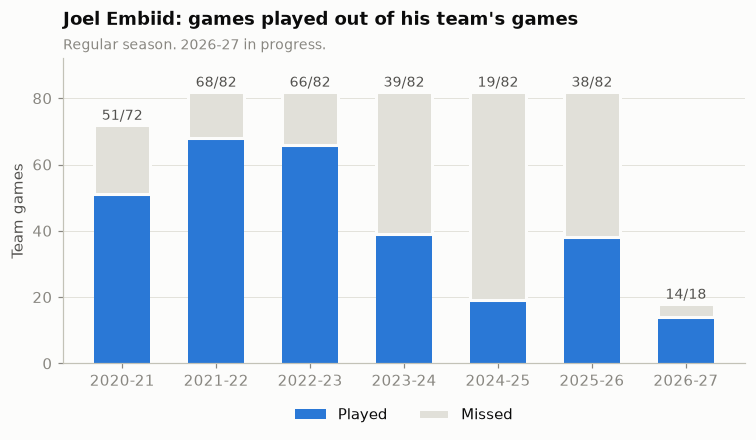

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(emb))
ax.bar(x, emb.gp, color=plotting.SERIES[0], width=0.6, label="Played")
ax.bar(x, emb.missed, bottom=emb.gp, color=plotting.GRID, width=0.6, label="Missed",
       edgecolor=plotting.SURFACE, linewidth=2)
for i, (gp, tg) in enumerate(zip(emb.gp, emb.team_games)):
    ax.text(i, tg + 1.5, f"{gp}/{tg}", ha="center", fontsize=9, color=plotting.INK_2)
ax.set_xticks(list(x), emb.index)
ax.set_ylabel("Team games")
ax.set_ylim(0, 92)
ax.set_title("Joel Embiid: games played out of his team's games", pad=22)
ax.text(0, 1.03, "Regular season. 2026-27 in progress.", transform=ax.transAxes, color=plotting.MUTED, fontsize=9)
ax.legend(loc="upper center", ncols=2, bbox_to_anchor=(0.5, -0.1))
plotting.save(fig, "0_embiid_games")

## Pool: on a roster, no games, already debuted (D1, D12)

In [6]:
played = set(zip(P.season, P.player_id))
no_games = R[[(s, p) not in played for s, p in zip(R.season, R.player_id)]].copy()
no_games["debut"] = no_games.player_id.map(debut)
no_games["debuted"] = no_games.debut < no_games.season.map(season_start)
pd.crosstab(no_games.season, no_games.debuted.map({True: "in pool, 0 games", False: "not yet debuted"}))

debuted,"in pool, 0 games",not yet debuted
season,,
2020-21,3,3
2021-22,10,3
2022-23,6,5
2023-24,7,3
2024-25,2,4
2025-26,4,1
2026-27,37,19


In [7]:
zero = no_games[no_games.debuted & no_games.season.isin(data.COMPLETE_SEASONS)]
zero[["season", "player_name", "team", "debut"]].sort_values(["season", "player_name"]).reset_index(drop=True)

,season,player_name,team,debut
0,2020-21,Jonathan Isaac,ORL,2017-10-18
1,2020-21,Klay Thompson,GSW,2011-12-25
2,2020-21,Zach Collins,POR,2017-10-20
3,2021-22,Ben Simmons,BKN,2017-10-18
4,2021-22,Dario Šarić,PHX,2016-10-26
5,2021-22,Jamal Murray,DEN,2016-10-26
6,2021-22,James Wiseman,GSW,2020-12-22
7,2021-22,John Wall,HOU,2010-10-28
8,2021-22,Jonathan Isaac,ORL,2017-10-18
9,2021-22,Kawhi Leonard,LAC,2011-12-26


## Player movement feed (D16)

In [8]:
print("Downloaded:", M.attrs["fetched_at"][:10], "| first:", M.date.min().date(), "| last:", M.date.max().date())
M["season"] = pd.cut(M.date, bins=[pd.Timestamp(f"{y}-07-01") for y in range(2015, 2028)],
                     labels=[data.season_label(y) for y in range(2015, 2027)], right=False)
pd.crosstab(M.season, M.type).loc[data.SEASONS]

Downloaded: 2026-11-24 | first: 2015-07-01 | last: 2026-11-23


type,AwardOnWaivers,ContractConverted,Signing,Trade,Waive
season,,,,,
2020-21,5,5,375,140,214
2021-22,6,21,571,141,293
2022-23,6,17,363,111,323
2023-24,3,19,440,125,322
2024-25,7,16,409,122,327
2025-26,2,13,419,116,375
2026-27,4,11,251,58,321


In [9]:
M[M.season.isin(data.SEASONS)].contract.value_counts().to_frame("signings and conversions")

,signings and conversions
contract,
Contract,840
Two-Way Contract,833
10-Day Contract,504
Rest-of-Season Contract,300
Rookie Scale Contract,215
NBA Contract,26
Substitute Player Contract,12


## Stint cases (D12)

In [10]:
Pc = P[P.season.isin(data.COMPLETE_SEASONS)]
cases = (Pc.sort_values("game_date")
           .groupby(["season", "player_id"])
           .agg(name=("player_name", "first"), teams=("team_id", "nunique"),
                last_team=("team_id", "last"), last_game=("game_date", "max"))
           .reset_index())
on_roster = set(zip(R.season, R.player_id, R.team_id))
cases["on_end_roster"] = [(s, p, t) in on_roster for s, p, t in zip(cases.season, cases.player_id, cases.last_team)]
cases["case"] = "Two or more teams"
cases.loc[(cases.teams == 1) & cases.on_end_roster, "case"] = "One team, on end roster"
cases.loc[(cases.teams == 1) & ~cases.on_end_roster, "case"] = "One team, not on end roster"
pd.crosstab(cases.season, cases.case, margins=True)

case,"One team, not on end roster","One team, on end roster",Two or more teams,All
season,,,,
2020-21,41,420,79,540
2021-22,97,411,97,605
2022-23,42,427,70,539
2023-24,47,447,78,572
2024-25,42,446,81,569
2025-26,56,454,72,582
All,325,2605,477,3407


In [11]:
team_dates = T.groupby(["season", "team_id"]).game_date.apply(list)
gone = cases[cases.case == "One team, not on end roster"].copy()
gone["games_after_last"] = [sum(d > last for d in team_dates[(s, t)])
                            for s, t, last in zip(gone.season, gone.last_team, gone.last_game)]

def exit_source(r):
    m = M[(M.player_id == r.player_id) & (M.date >= r.last_game) & (M.date <= season_end[r.season])]
    if m.type.isin(["Waive", "Trade"]).any():
        return "Dated waiver or trade"
    signed = M[(M.player_id == r.player_id) & (M.date <= r.last_game) & M.contract.notna()]
    if len(signed) and signed.contract.iloc[-1] == "10-Day Contract":
        return "10-day contract (ends 10 days after signing)"
    if len(signed) and signed.contract.iloc[-1] == "Two-Way Contract":
        return "Two-way, no exit date (flagged)"
    return "No information (flagged)"

gone["exit"] = gone.apply(exit_source, axis=1)
gone.exit.value_counts().to_frame("player-seasons")

,player-seasons
exit,
Dated waiver or trade,191
10-day contract (ends 10 days after signing),125
No information (flagged),6
"Two-way, no exit date (flagged)",3


In [12]:
spans = (Pc.groupby(["season", "player_id", "player_name", "team_id"]).game_date.agg(["min", "max"])
           .reset_index().sort_values(["season", "player_id", "min"]))
rows = []
for (season, pid, name), d in spans.groupby(["season", "player_id", "player_name"]):
    d = d.reset_index(drop=True)
    for i in range(1, len(d)):
        old, new = d.loc[i - 1], d.loc[i]
        gap = sum(old["max"] < x < new["min"] for x in team_dates[(season, new.team_id)])
        dated = ((M.player_id == pid) & M.type.isin(["Trade", "Waive", "Signing", "AwardOnWaivers"])
                 & (M.date >= old["max"]) & (M.date <= new["min"])).any()
        rows.append((season, name, team_abbr[old.team_id], team_abbr[new.team_id], gap, dated))
moves = pd.DataFrame(rows, columns=["season", "player", "from", "to", "new_team_games_in_gap", "dated_in_feed"])
moves.dated_in_feed.value_counts().rename({True: "dated in feed", False: "not dated"}).to_frame("team changes")

,team changes
dated_in_feed,
dated in feed,509
not dated,6


PosixPath('outputs/figures/0_stint_gaps.png')

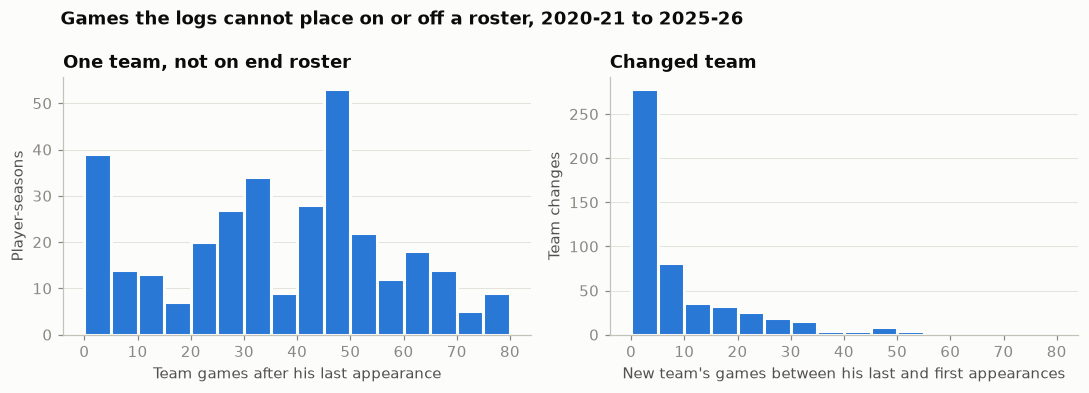

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
bins = range(0, 85, 5)
axes[0].hist(gone.games_after_last, bins=bins, color=plotting.SERIES[0], edgecolor=plotting.SURFACE, linewidth=2)
axes[0].set_title("One team, not on end roster")
axes[0].set_xlabel("Team games after his last appearance")
axes[0].set_ylabel("Player-seasons")
axes[1].hist(moves.new_team_games_in_gap, bins=bins, color=plotting.SERIES[0], edgecolor=plotting.SURFACE, linewidth=2)
axes[1].set_title("Changed team")
axes[1].set_xlabel("New team's games between his last and first appearances")
axes[1].set_ylabel("Team changes")
fig.suptitle("Games the logs cannot place on or off a roster, 2020-21 to 2025-26", x=0.06, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save(fig, "0_stint_gaps")

In [14]:
moves[moves.player.isin(["Kevin Durant", "James Harden"])].reset_index(drop=True)

,season,player,from,to,new_team_games_in_gap,dated_in_feed
0,2020-21,James Harden,HOU,BKN,1,True
1,2021-22,James Harden,BKN,PHI,7,True
2,2022-23,Kevin Durant,BKN,PHX,21,True
3,2025-26,James Harden,LAC,CLE,2,True


## Save

In [15]:
out = PROJECT_ROOT / "data" / "processed"
P.to_parquet(out / "player_games.parquet", index=False)
T.to_parquet(out / "team_games.parquet", index=False)
R.to_parquet(out / "rosters.parquet", index=False)
M.drop(columns="season").to_parquet(out / "player_movement.parquet", index=False)
debut.reset_index().to_parquet(out / "debuts.parquet", index=False)
[str(f.relative_to(PROJECT_ROOT)) for f in sorted(out.glob("*.parquet"))]

['data/processed/debuts.parquet',
 'data/processed/player_games.parquet',
 'data/processed/player_movement.parquet',
 'data/processed/rosters.parquet',
 'data/processed/team_games.parquet']